# EV Charging Demand Regression Project

## Project objective
The regression model goal is to predict the charging demand of an EV charging session using regression models.

We give the model information about a charging session, such as:
- charging duration,
- month/day/hour,
- location,
- charger type/company,
- previous usage counts,
and ask the model to estimate the numerical **demand** value.

### Complete workflow
1. Load and prepare the dataset.
2. Select the final numerical and categorical model features.
3. Check the dataset size, columns, and missing values.
4. Check simple correlations with the target (`demand`).
5. Separate input features (`X`) and target (`y`).
6. Use a chronological 80/20 train-test split.
7. Preprocess numeric and categorical features.
8. Train six regression models.
9. Compare MAE, MSE, RMSE, R², and Train/Test R².
10. Inspect LightGBM feature importance.
11. Study residual graphs to understand model errors.

### Important terms
- **Feature:** an input column used to make a prediction.
- **Target:** the value we want to predict. Here, the target is `demand`.
- **Training data:** data used by the model to learn patterns.
- **Test data:** later unseen data used to check whether the learned pattern generalizes.
- **Regression:** a machine-learning task that predicts a numerical value.

## 1. Load the feature-engineered dataset and sort it chronologically

Before training a model, we prepare a clean modeling dataset.

The **first 80%** of rows for training and the **last 20%** for testing. Therefore, sorting by `start_full` first ensures that training uses older records and testing uses newer records.

In [37]:
import pandas as pd

# 1. Load the feature-engineered EV charging dataset
df = pd.read_csv('data/ev_charging_featured.csv')

# 2. Convert the starting timestamp to datetime and sort records from oldest to newest
# This order is required for the chronological train-test split used later.
df['start_full'] = pd.to_datetime(df['start_full'])
df = df.sort_values("start_full").reset_index(drop=True)

## 2. Dataset size

`df.shape` returns: (rows and column records)

The output is **(72,241, 17)**, which means:
- **72,241 charging-session records**
- **17 remaining columns**

In [38]:
df.shape

(72241, 17)

## 3. columns

- **Target:** `demand`
- **Main numerical/session feature:** `duration`
- **Calendar/time features:**  `start_day`, `start_hour`, `start_minute`, `week_of_year`
- **Categorical/context features:** `chargercompany`, `location`, `chargertype`, `time_of_day`, `day_type`, `month_name`, `day_name`
- **Historical usage features:** `user_previous_sessions`,`location_previous_sessions`,`charger_previous_sessions`

In [39]:
df.columns

Index(['chargercompany', 'location', 'chargertype', 'duration', 'demand',
       'start_full', 'start_hour', 'start_day', 'start_minute', 'week_of_year',
       'day_name', 'month_name', 'day_type', 'time_of_day',
       'user_previous_sessions', 'charger_previous_sessions',
       'location_previous_sessions'],
      dtype='object')

## 4. Missing-value check

Check missing values column by column and all selected columns by using `df.isnull().sum()`.

### Output
Every column shows **0**, so there are no missing values in the current modeling dataset.

In [40]:
df.isnull().sum()

chargercompany                0
location                      0
chargertype                   0
duration                      0
demand                        0
start_full                    0
start_hour                    0
start_day                     0
start_minute                  0
week_of_year                  0
day_name                      0
month_name                    0
day_type                      0
time_of_day                   0
user_previous_sessions        0
charger_previous_sessions     0
location_previous_sessions    0
dtype: int64

## 5. Feature availability validation

Check required `features` are available in dataframe.

- The list stores the feature names that should exist.
- The list comprehension checks each expected feature against `df.columns`.
- Any absent feature is stored in `missing_cols`.
- If the list is empty, the code prints that all features are present.

The output confirms that **all required features are available**.

In [41]:
features = [
    "duration",
    "start_day",
    "start_hour",
    "start_minute",
    "week_of_year",
    "user_previous_sessions",
    "charger_previous_sessions",
    "location_previous_sessions",
    "chargercompany",
    "location",
    "chargertype",
    "month_name",
    "day_name",
    "day_type",
    "time_of_day"
]

# Check whether every required modeling feature exists in the DataFrame
missing_cols = [col for col in features if col not in df.columns]

# Report the result clearly
if not missing_cols:
    print("All features are present in the DataFrame!")
else:
    print(f"Missing columns ({len(missing_cols)}):", missing_cols)
    

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

All features are present in the DataFrame!


## 6. Correlation with demand

Correlation measures the **linear relationship** between two numerical variables.

- Close to **+1** → strong positive linear relationship.
- Close to **0** → weak/no linear relationship.
- Close to **-1** → strong negative linear relationship.

The code first keeps numerical columns, calculates the correlation matrix, selects only correlations with `demand`, and sorts them from highest to lowest.

### Interpretation
- `demand = 1.0000` appears because a variable is perfectly correlated with itself.
- `duration = 0.6009` has the strongest positive linear relationship with demand.
- `start_hour = 0.1283` has only a weak positive linear relationship.
- Most other features have weak individual linear relationships with demand. However, tree-based models can still use them effectively through nonlinear patterns and feature interactions.

Also, `chargercompany` and `chargertype` appear in this numeric correlation because they are numerically stored in the DataFrame, but later treats them as **categorical features**.

In [42]:
# Select only columns currently stored as numeric and calculate pairwise correlations
corr = df.select_dtypes(include='number').corr()

# Show each numeric column's correlation with the target and sort from highest to lowest
corr['demand'].sort_values(
    ascending=False
)

demand                        1.000000
duration                      0.600884
start_hour                    0.128282
chargertype                   0.062465
chargercompany                0.041412
location_previous_sessions    0.015141
charger_previous_sessions     0.012825
start_day                    -0.006460
week_of_year                 -0.006950
start_minute                 -0.007296
user_previous_sessions       -0.036799
Name: demand, dtype: float64

## 7. Imports, feature groups, target, chronological split, and preprocessing

### A. Imported tools
- `numpy` is used for numerical calculations such as square root.
- `Pipeline` joins preprocessing and a model into one safe workflow.
- `ColumnTransformer` applies different preprocessing to numeric and categorical columns.
- `StandardScaler` scales numerical columns.
- `OneHotEncoder` converts categorical values into machine-readable dummy columns.
- `mean_absolute_error`, `mean_squared_error`, and `r2_score` evaluate regression predictions.
- `LinearRegression` is the first regression model used later.

### B. Numeric features
The numerical model inputs are:
- charging duration,
- calendar/time values,
- previous-session counts.

### C. Categorical features
The categorical model inputs are:
- location,
- time of day,
- charger type,
- charger company,
- `day_type`, `month_name`, and `day_name`.

### D. Features (`X`) and target (`y`)
- `x` = columns given to the model as inputs.
- `y` = `demand`, the numerical value the model must predict.

### E. Chronological 80/20 split
`split_idx = int(len(df) * 0.80)` finds the row that separates the first 80% from the last 20%.

Because the DataFrame was already sorted by `start_full`:
- earliest 80% → training data,
- latest 20% → test data.

No random shuffle is used.

For time-related data, we want to imitate the real situation: **learn from the past and predict newer records**. Randomly mixing future rows into training could give an unrealistically easy test.

### F. Preprocessing
For numerical features:
- `StandardScaler()` transforms values to a common scale, roughly centered around mean 0 with standard deviation 1.

For categorical features:
- `OneHotEncoder(...)` creates binary dummy columns.
- `drop='first'` removes one dummy level from each category group.
- `handle_unknown='ignore'` prevents an error if a category appears in test data that was not seen during training.

ColumnTransformer applies scaling to numerical features, standard One-Hot Encoding to regular categorical features, and predefined-category One-Hot Encoding to calendar features.

log_duration was explored during EDA but was not retained in the final model because the original duration feature was easier to interpret and already contained the same underlying session-length information.

The model assumes that an expected charging duration is available when the prediction is made. If duration is known only after the charging session finishes, it would not be suitable as an input for a real-time prediction made at session start.

### Leakage protection
Because preprocessing is placed inside a `Pipeline`, scaling and encoding are **fit on the training data** when the pipeline is trained, then applied to the test data. This avoids learning preprocessing information from the test set.

### Note about tree models
Decision Tree, Random Forest, LightGBM, Gradient Boosting, and XGBoost generally do not require numerical scaling. However, using the same preprocessing pipeline gives a consistent input workflow across all models.

In [43]:
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

numeric_features = [
    "duration",
    "start_day",
    "start_hour",
    "start_minute",
    "week_of_year",
    "user_previous_sessions",
    "charger_previous_sessions",
    "location_previous_sessions"
]

standard_categorical_features = [
    "chargercompany",
    "location",
    "chargertype",
    "day_type",
    "time_of_day"
]

calendar_categorical_features = [
    "month_name",
    "day_name"
]

expected_months = set(month_order)
expected_days = set(day_order)

assert set(df["month_name"].unique()).issubset(
    expected_months
), "Unexpected month name found."

assert set(df["day_name"].unique()).issubset(
    expected_days
), "Unexpected day name found."

# 3. Separate model inputs (x) and regression target (y)
x = df[numeric_features + standard_categorical_features + calendar_categorical_features]
y = df['demand']

# 4. Create an 80/20 chronological split.
# The DataFrame was sorted by start time earlier, so no shuffling is used.
split_idx = int(len(df) * 0.80)

x_train = x.iloc[:split_idx]
x_test = x.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print("Training date range:")
print(df["start_full"].iloc[:split_idx].min())
print(df["start_full"].iloc[:split_idx].max())

print("\nTesting date range:")
print(df["start_full"].iloc[split_idx:].min())
print(df["start_full"].iloc[split_idx:].max())

# 5. Build preprocessing:
#    - scale numerical features
#    - one-hot encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            standard_categorical_features
        ),
        (
            "calendar",
            OneHotEncoder(
                categories=[
                    month_order,
                    day_order
                ],
                drop="first",
                handle_unknown="ignore"
            ),
            calendar_categorical_features
        )
    ]
)


Training date range:
2021-09-30 17:14:26
2022-07-30 20:10:46

Testing date range:
2022-07-30 20:10:47
2022-09-30 23:11:59


# 8. Model 1 — Linear Regression

Linear Regression tries to predict the target using a **straight-line/linear relationship** between the input features and demand.

**Predicted demand = intercept + contributions from the input features**

Each feature receives a coefficient. The model combines those coefficients to make a numerical prediction.

### usage
- Simple and easy to explain.
- Fast to train.
- Good baseline model.
- Helps us see whether the problem can be represented reasonably well by a linear relationship.

### Limitation
If the true relationship between features and demand is nonlinear or contains complex interactions, Linear Regression may miss those patterns.

In [44]:
# 1. Build a pipeline: preprocessing first, then Linear Regression
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# 2. Train the model using the older 80% of records
lr_pipeline.fit(x_train, y_train)

# 3. Predict demand for the newer 20% test records
y_pred_lr = lr_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

# 5. Print test metrics and compare training R² with test R²
print("=== Linear Regression Results (Standard Features Only) ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")


=== Linear Regression Results (Standard Features Only) ===
MAE  (Mean Absolute Error) : 7.1171
MSE  (Mean Squared Error)  : 112.6245
RMSE (Root Mean Sq Error)  : 10.6125
R² Score                   : 0.4158


### Linear Regression results

**Observed test results**
- MAE = **7.1171**
- MSE = **112.6245**
- RMSE = **10.6125**
- R² = **0.4158**

#### Interpretation
MAE says the predictions differ from the actual demand by about **7.12 units on average**.

RMSE is higher at **10.61**, which tells us that some larger errors are present because RMSE penalizes large errors more strongly.

Test R² = **0.4158** means the model captures about **41.6% of the variation in unseen test demand**.

**Conclusion:** Linear Regression provides a useful baseline model. However, its relatively low Test R² suggests that charging demand depends on nonlinear relationships that cannot be fully captured by a simple linear model.

# 9. Model 2 — Decision Tree Regressor

A Decision Tree predicts a numerical value by repeatedly splitting the data into smaller groups using questions such as:

- Is duration below a particular value?
- Is the start hour above a particular value?
- Is the location one category or another?

After several splits, a final leaf gives the predicted demand.

### usage
- Can learn **nonlinear** relationships.
- Can capture feature interactions.
- Does not require a straight-line relationship.
- `max_depth` limits how many levels the tree can grow. A very deep tree can memorize training data, so limiting depth is one way to reduce overfitting.

In [45]:
from sklearn.tree import DecisionTreeRegressor

# 1. Build a Decision Tree pipeline.
# max_depth=10 limits tree growth to reduce excessive memorization.
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(max_depth=10, random_state=42))
])

# 2. Train the model
dt_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_dt = dt_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_dt)
mse = mean_squared_error(y_test, y_pred_dt)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dt)

# 5. Print test metrics and compare training R² with test R²
print("=== Decision Tree Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")

=== Decision Tree Regressor Results ===
MAE  (Mean Absolute Error) : 4.9781
MSE  (Mean Squared Error)  : 89.3586
RMSE (Root Mean Sq Error)  : 9.4530
R² Score                   : 0.5365


### Decision Tree results

**Observed test results**
- MAE = **4.9781**
- MSE = **89.3586**
- RMSE = **9.4530**
- R² = **0.5365**

### interpretation

The Decision Tree improves all test metrics compared with Linear Regression. This means nonlinear splitting captures more useful structure.

**Conclusion:** better predictive power than Linear Regression

# 10. Model 3 — LightGBM Regressor

LightGBM is a **gradient-boosting tree model**.

Instead of building one tree only, it builds many small trees. Each new tree tries to improve the errors made by the previous trees. Their combined prediction is usually much stronger than a single tree.

### Main parameters used here
- `n_estimators=100`: build 100 boosting trees.
- `learning_rate=0.1`: controls how strongly each new tree changes the overall prediction.
- `random_state=42`: makes the experiment more reproducible.
- `verbose=-1`: suppresses training messages.

### usage
LightGBM is good at:
- nonlinear patterns,
- feature interactions,
- larger tabular datasets,
- complex relationships that Linear Regression may miss.

In [46]:
import lightgbm as lgb

# 1. Build the LightGBM pipeline
lgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', lgb.LGBMRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        verbose=-1
    ))
])

# 2. Train the boosting model
lgb_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_lgb = lgb_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_lgb)
mse = mean_squared_error(y_test, y_pred_lgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lgb)

# 5. Print test metrics and compare training R² with test R²
print("=== LightGBM Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")

=== LightGBM Regressor Results ===
MAE  (Mean Absolute Error) : 4.1510
MSE  (Mean Squared Error)  : 54.5723
RMSE (Root Mean Sq Error)  : 7.3873
R² Score                   : 0.7169


### LightGBM results

**Observed test results**
- MAE = **4.1510**
- MSE = **54.5723**
- RMSE = **7.3873**
- R² = **0.7169**

### interpretation
This is the strongest result in the notebook:
- the average absolute error is the lowest,
- large-error-sensitive RMSE is also the lowest,
- Test R² is the highest.

A Test R² of **0.7169** means the model captures about **71.7% of the variation in the test demand values**.

**Conclusion:** LightGBM was selected as the final regression model because it achieved the lowest prediction errors (MAE, MSE, RMSE) and the highest Test R² score among all evaluated models.

# 11. Model 4 — Gradient Boosting Regressor

Gradient Boosting also builds trees **sequentially**.

The first tree makes an initial prediction. The next tree focuses on correcting remaining errors. This process repeats, and all trees work together to produce the final prediction.

### Main parameters used here
- `n_estimators=100`: number of boosting stages.
- `learning_rate=0.1`: contribution of each new stage.
- `max_depth=5`: limits the depth of each individual tree.
- `random_state=42`: reproducibility.

### usage
It can model nonlinear relationships and usually performs much better than a single Decision Tree when the parameters are suitable.

In [47]:
from sklearn.ensemble import GradientBoostingRegressor

# 1. Build the Gradient Boosting pipeline
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ))
])

# 2. Train the model
gb_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_gb = gb_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_gb)
mse = mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_gb)

# 5. Print test metrics and compare training R² with test R²
print("=== Gradient Boosting Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")

=== Gradient Boosting Regressor Results ===
MAE  (Mean Absolute Error) : 4.2880
MSE  (Mean Squared Error)  : 56.5744
RMSE (Root Mean Sq Error)  : 7.5216
R² Score                   : 0.7065


### Gradient Boosting results

**Observed test results**
- MAE = **4.2880**
- MSE = **56.5744**
- RMSE = **7.5216**
- R² = **0.7065**

### Interpretation

The model captures about **70.7% of test-set variation** and has much lower error than Linear Regression or the single Decision Tree.

It is a strong model, but LightGBM has slightly lower error and slightly higher Test R².

**Conclusion:** strong model, slightly behind LightGBM and XGBoost models.

# 12. Model 5 — XGBoost Regressor

XGBoost is another powerful gradient-boosting tree algorithm.

Like other boosting methods, it adds trees step by step so later trees correct earlier errors. XGBoost also includes optimization and regularization techniques designed to make boosting efficient and control overfitting.

### Main parameters used here
- `n_estimators=100`: number of trees.
- `learning_rate=0.1`: size of each boosting update.
- `max_depth=5`: maximum depth of individual trees.
- `random_state=42`: reproducibility.

In [48]:
import xgboost as xgb

# 1. Build the XGBoost pipeline
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb.XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ))
])

# 2. Train the model
xgb_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_xgb = xgb_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_xgb)
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_xgb)

# 5. Print test metrics and compare training R² with test R²
print("=== XGBoost Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")

=== XGBoost Regressor Results ===
MAE  (Mean Absolute Error) : 4.2383
MSE  (Mean Squared Error)  : 55.9723
RMSE (Root Mean Sq Error)  : 7.4815
R² Score                   : 0.7097


### XGBoost results

**Observed test results**
- MAE = **4.2383**
- MSE = **55.9723**
- RMSE = **7.4815**
- R² = **0.7097**

### Interpretation
XGBoost captures about **71.0% of the variation in unseen test demand**.

Its result is very close to LightGBM:
- LightGBM Test R² = 0.7169
- XGBoost Test R² = 0.7097

LightGBM still has slightly lower MAE/RMSE and slightly higher Test R².

**Conclusion:** Second best model, very close to LightGBM.

# 13. Model 6 — Random Forest Regressor

Random Forest builds **many Decision Trees independently** using random samples and random subsets of features. The final regression prediction is the average of the trees' predictions.

### Why is it different from boosting?
- **Random Forest:** many trees are built more independently and then averaged.
- **Boosting:** trees are built sequentially, where each new tree tries to correct previous errors.

### Main parameters used here
- `n_estimators=100`: build 100 trees.
- `max_depth=12`: limits the depth of each tree.
- `random_state=42`: reproducibility.
- `n_jobs=-1`: use all available CPU cores for training.

### usage
Averaging many trees usually makes Random Forest more stable than a single Decision Tree and reduces variance.

In [49]:
from sklearn.ensemble import RandomForestRegressor

# 1. Build a Random Forest pipeline.
# n_jobs=-1 uses all available CPU cores for faster training.
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Train the model
rf_pipeline.fit(x_train, y_train)

# 3. Predict test-set demand
y_pred_rf = rf_pipeline.predict(x_test)

# 4. Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

# 5. Print test metrics and compare training R² with test R²
print("=== Random Forest Regressor Results ===")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)  : {mse:.4f}")
print(f"RMSE (Root Mean Sq Error)  : {rmse:.4f}")
print(f"R² Score                   : {r2:.4f}")

=== Random Forest Regressor Results ===
MAE  (Mean Absolute Error) : 4.5739
MSE  (Mean Squared Error)  : 59.8254
RMSE (Root Mean Sq Error)  : 7.7347
R² Score                   : 0.6897


### Random Forest results

**Observed test results**
- MAE = **4.5739**
- MSE = **59.8254**
- RMSE = **7.7347**
- R² = **0.6897**

### interpretation

Random Forest captures about **68.9% of the test variation**, so it performs much better than Linear Regression and the single Decision Tree.

**Conclusion:** strong model, but boosting models generalize better in this experiment.

# 14. Final model comparison and project interpretation

## evaluation metrics

All six models are evaluated on the **same chronological test set**, so their metrics are directly comparable.

## Results

| Model | MAE ↓ | MSE ↓ | RMSE ↓ | R² ↑ |
|---|---:|---:|---:|---:|
| Linear Regression | 7.1171 | 112.6245 | 10.6125 | 0.4158 | 
| Decision Tree | 4.9781 | 89.3586 | 9.4530 | 0.5365 | 
| LightGBM | **4.1510** | **54.5723** | **7.3873** | **0.7169** | 
| Gradient Boosting | 4.2880 | 56.5744 | 7.5216 | 0.7065 |
| XGBoost | 4.2383 | 55.9723 | 7.4815 | 0.7097 | 
| Random Forest | 4.5739 |59.8254  | 7.7347 | 0.6897 |

## Model-by-model interpretation

### 1. Linear Regression
- MAE = **7.1171**
- RMSE = **10.6125**
- R² = **0.4158**

This is the weakest model in the comparison. It captures about **41.6% of the test-set variation**. A simple linear relationship is not flexible enough for the data.

### 2. Decision Tree
- MAE = **4.9781**
- RMSE = **9.4530**
- R² = **0.5365**

### 3. LightGBM
- MAE = **4.1510**
- RMSE = **7.3873**
- R² = **0.7169**

LightGBM gives the **lowest MAE, lowest MSE, lowest RMSE, and highest Test R²** in this notebook. It therefore provides the strongest overall predictive performance among the tested models.

### 4. Gradient Boosting
- MAE = **4.2880**
- RMSE = **7.5216**
- R² = **0.7065**

### 5. XGBoost
- MAE = **4.2383**
- RMSE = **7.4815**
- Test R² = **0.7097**

XGBoost is the **second-best model by Test R²** and is very close to LightGBM.

### 6. Random Forest
- MAE = **4.5739**
- RMSE = **7.7395**
- R² = **0.6893**

## Final model choice
Based on the interpretation, **LightGBM is the best model among the six tested regression models** because it has:
- the lowest MAE,
- the lowest MSE,
- the lowest RMSE,
- the highest Test R².

# 15. LightGBM feature importance

Since LightGBM gives the best test metrics among the six models ,this section examines which features it used most often.

`model.feature_importances_` returns LightGBM's default **split importance**: how many times a feature was used to split the training data across the trees.

Therefore:
- higher importance means the feature contributed more frequently to decision-making splits across the LightGBM trees.
- it does **not** mean the feature increases demand,
- it does **not** mean an importance value of 825 equals 825 units of demand.

### How the code works
1. Get the trained LightGBM model from the pipeline.
2. Reconstruct all final feature names:
   - numeric feature names remain the same,
   - categorical values have been one-hot encoded into new dummy columns.
3. Pair each feature name with its importance score.
4. Sort from highest importance to lowest.
5. Display the top 20.

### Output
The strongest features are:
1. `duration` — 811
2. `user_previous_sessions` — 409
3. `location_previous_sessions` — 271
4. `charger_previous_sessions` — 251
5. `start_hour` — 238

This tells us that **charging duration and historical charging behavior are very influential for this LightGBM model**, while time and location/charger context also contribute.

In [50]:
# Extract The Trained LightGBM Model And Preprocessor

model = lgb_pipeline.named_steps["model"]

fitted_preprocessor = (
    lgb_pipeline.named_steps["preprocessor"]
)

# Get All Feature Names After Preprocessing
feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

# Remove transformer prefixes such as:
# num__duration
# cat__location_hotel
# calendar__month_name_January

clean_feature_names = [
    feature_name.split("__", 1)[-1]
    for feature_name in feature_names
]

# Check That Feature Counts Match
print(
    "Number Of Transformed Features:",
    len(clean_feature_names)
)

print(
    "Number Of Importance Scores:",
    len(model.feature_importances_)
)

assert (
    len(clean_feature_names)
    == len(model.feature_importances_)
), (
    "Feature-name count does not match "
    "the model-importance count."
)

# Create The Feature-Importance DataFrame
importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Importance": model.feature_importances_
})

# Sort from highest to lowest importance
importance_df = (
    importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# Display the 20 most important features
print(
    importance_df
    .head(20)
    .to_string(index=False)
)

Number Of Transformed Features: 44
Number Of Importance Scores: 44
                    Feature  Importance
                   duration         811
     user_previous_sessions         409
 location_previous_sessions         271
  charger_previous_sessions         251
                 start_hour         238
               week_of_year         174
           chargercompany_1         125
               start_minute         105
              chargertype_1          80
                  start_day          75
            location_market          55
         location_apartment          53
location_public institution          49
             location_hotel          41
       location_public area          35
            location_resort          29
           location_company          22
location_public parking lot          21
        time_of_day_Evening          20
        location_bus garage          14


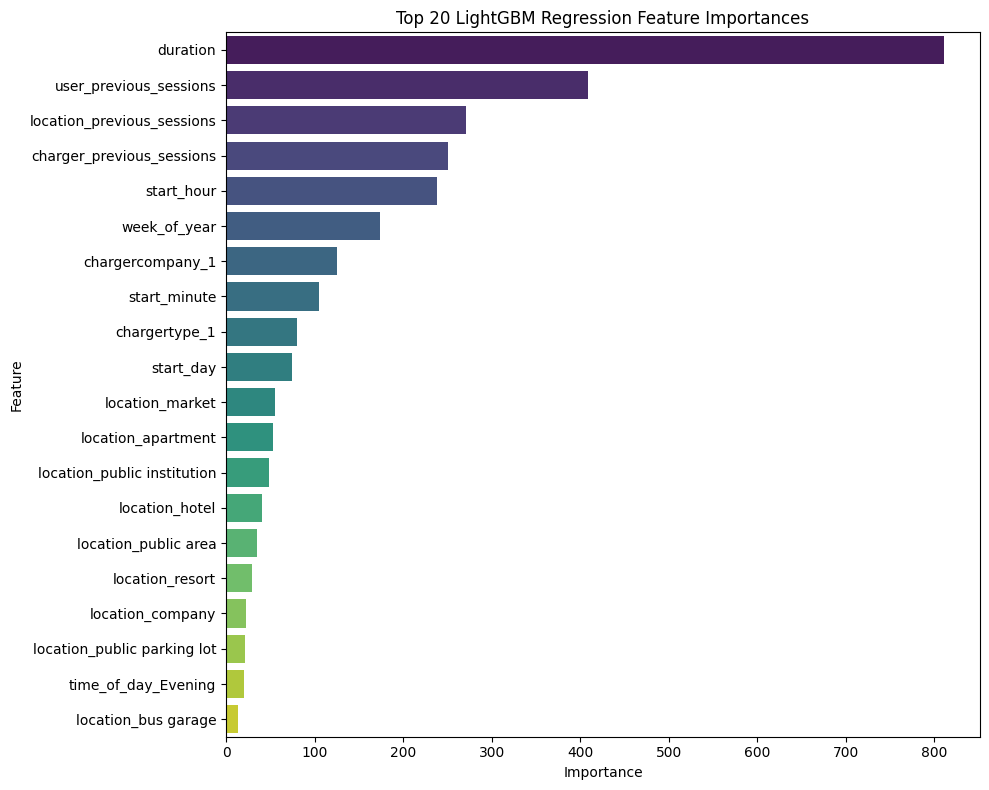

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

top_features = (
    importance_df
    .head(20)
    .sort_values(
        by="Importance",
        ascending=False
    )
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title(
    "Top 20 LightGBM Regression Feature Importances"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "images/lightgbm_regression_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 16. Residual analysis

A residual is the prediction error for one record.

**Residual = Actual demand - Predicted demand**

Therefore:
- residual = **0** → perfect prediction,
- residual **> 0** → actual demand was higher than predicted → model **underpredicted**,
- residual **< 0** → predicted demand was higher than actual → model **overpredicted**.

## usage
Evaluation metrics give one summary number, but residual plots show **where and how the model makes mistakes**.

Each model produces two graphs:

### Left graph — Residual Distribution
This histogram shows how residual errors are distributed.

- a tall concentration close to 0,
- fewer very large positive or negative errors.

Long tails mean some records have large prediction errors.

### Right graph — Residual vs Predicted Demand
- X-axis = predicted demand.
- Y-axis = residual.
- Red dashed line = residual 0, meaning perfect prediction.

An ideal residual plot looks like a random cloud around the red zero line with a fairly similar vertical spread across prediction values.

Patterns such as a triangle, funnel, curve, or bands tell us the errors are systematic rather than completely random.

### concept
residual is calculated as `actual - predicted`:
- dots **above** the red line = underprediction,
- dots **below** the red line = overprediction.

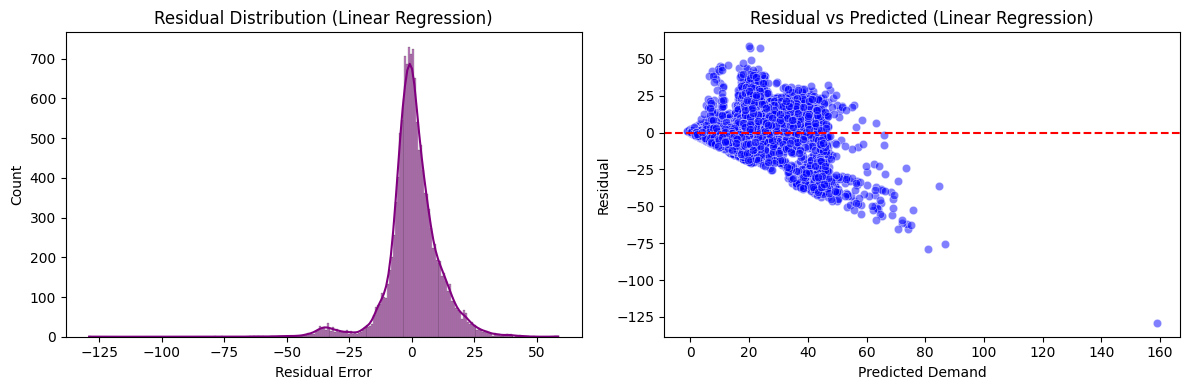

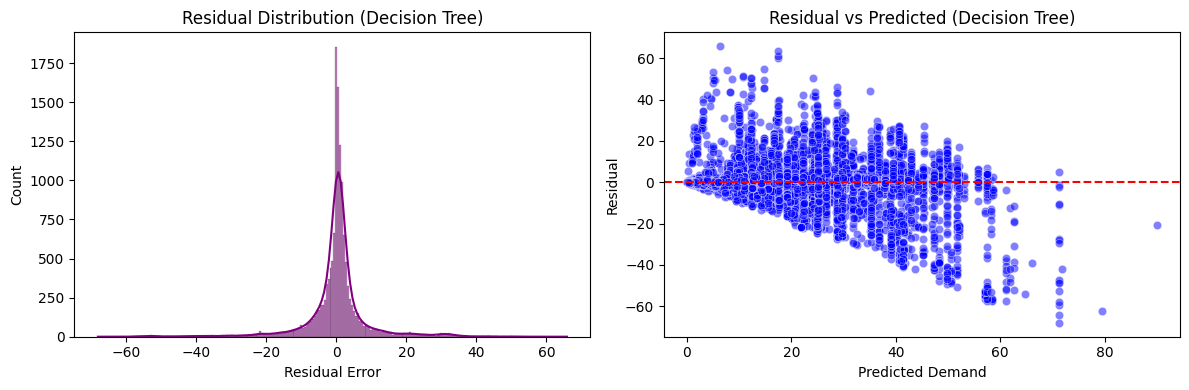

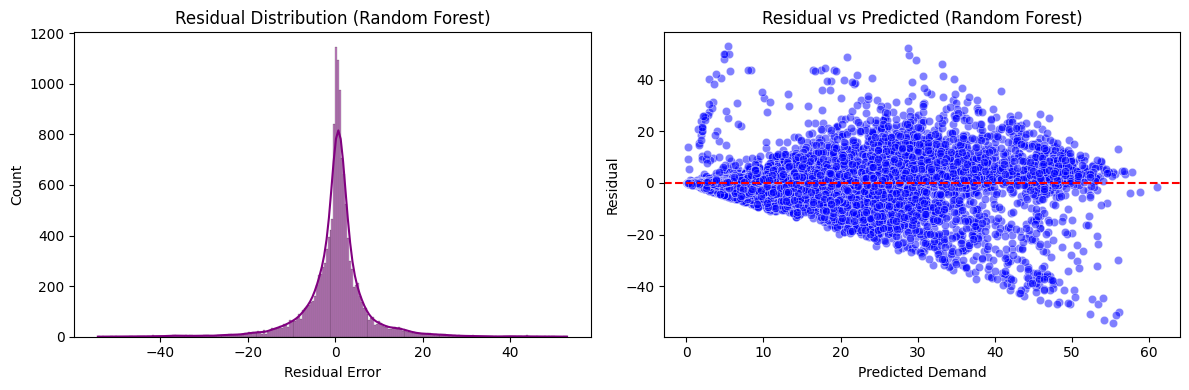

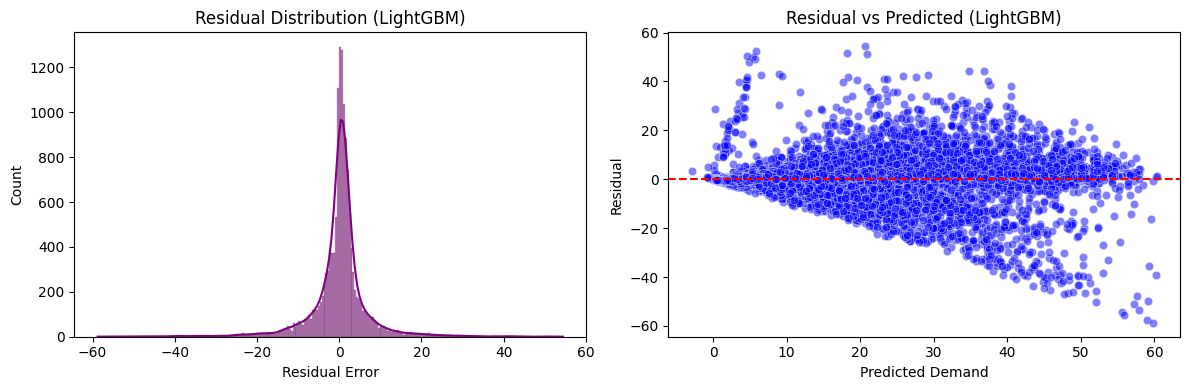

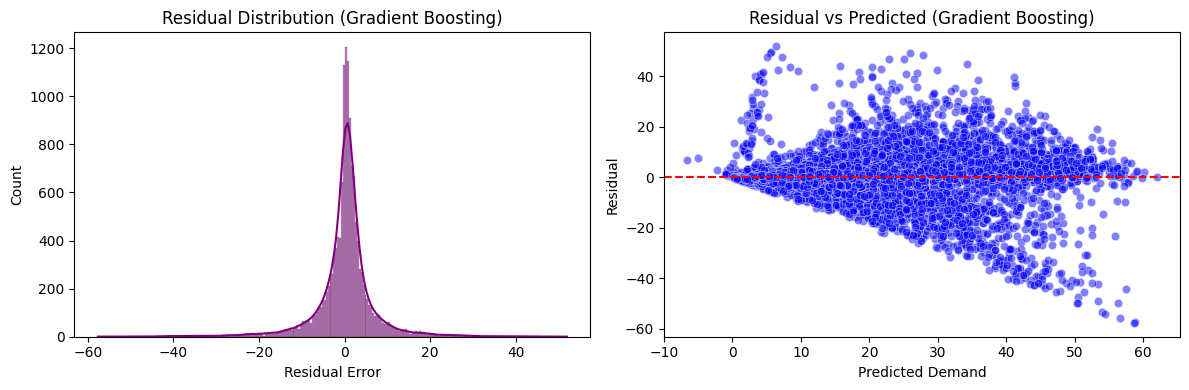

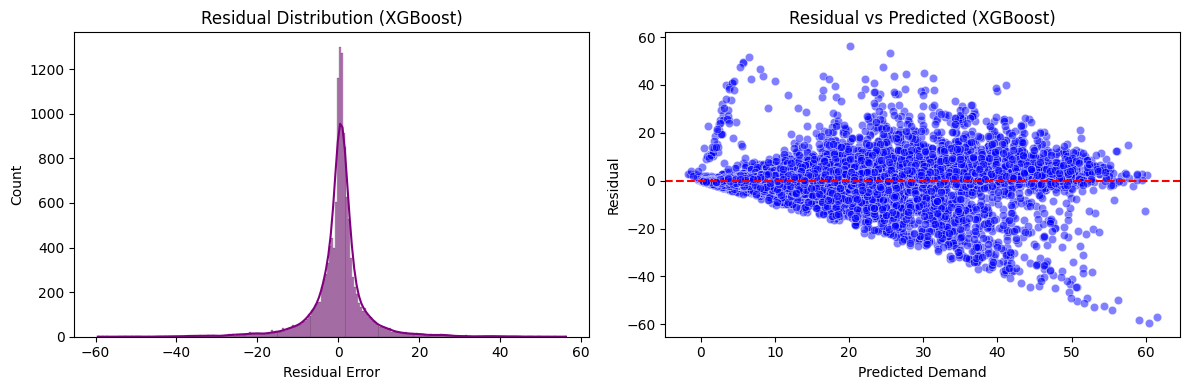

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create a folder to store dashboard images
os.makedirs("images", exist_ok=True)

def analyze_residuals(y_test, y_pred, model_name):
    # Residual = actual demand - predicted demand
    residuals = y_test - y_pred

    # Create one figure containing two residual-analysis plots
    plt.figure(figsize=(12, 4))

    # Left plot: distribution of residual errors
    plt.subplot(1, 2, 1)
    sns.histplot(residuals, kde=True, color='purple')
    plt.title(f"Residual Distribution ({model_name})")
    plt.xlabel("Residual Error")

    # Right plot: residual error against predicted demand
    plt.subplot(1, 2, 2)
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.5, color='blue')
    plt.axhline(0, color='red', linestyle="--")
    plt.title(f"Residual vs Predicted ({model_name})")
    plt.xlabel("Predicted Demand")
    plt.ylabel("Residual")

    # Prevent plot labels from overlapping
    plt.tight_layout()

    file_name = model_name.lower().replace(" ", "_")

    plt.savefig(
        f"images/residual_{file_name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    
    plt.show()


# Generate residual plots for all six regression models
analyze_residuals(y_test, y_pred_lr, "Linear Regression")
analyze_residuals(y_test, y_pred_dt, "Decision Tree")
analyze_residuals(y_test, y_pred_rf, "Random Forest")
analyze_residuals(y_test, y_pred_lgb, "LightGBM")
analyze_residuals(y_test, y_pred_gb, "Gradient Boosting")
analyze_residuals(y_test, y_pred_xgb, "XGBoost")


## Residual graph interpretation for each model

### 1. Linear Regression
**Residual distribution graph:** Most errors are near zero, but the distribution has long tails, including a very large negative error.

**Residual vs predicted graph:** The points form a strong triangular/downward pattern instead of a random cloud. As predicted demand becomes larger, many residuals move far below zero.

Because negative residual means overprediction, this shows that the model often predicts **too high** for many larger predicted-demand cases. Some positive residuals also show underprediction.

The linear model is missing important nonlinear structure. This supports its relatively low Test R² of 0.4158.

### 2. Decision Tree
**Residual distribution graph:** Residuals are more tightly centered around zero than Linear Regression.

**Residual vs predicted graph:** There are visible vertical bands and a widening/structured spread rather than a random cloud. Many higher predictions have strongly negative residuals.

### 3. Random Forest
**Residual distribution graph:** The residual distribution is narrower and strongly concentrated around zero.

**Residual vs predicted graph:** The cloud is more centered around zero, but a triangular/funnel shape is still visible. The spread becomes large in some middle-to-high prediction ranges, including many negative residuals.

### 4. LightGBM
**Residual distribution graph:** Residuals are sharply concentrated around zero, with fewer large errors than the weaker models.

**Residual vs predicted graph:** The cloud is relatively balanced near zero for many cases, although a funnel/triangular pattern remains as predicted demand increases. Some high-prediction cases still fall far below zero.

### 5. Gradient Boosting
**Residual distribution graph:** Most residuals are near zero, with tails on both sides.

**Residual vs predicted graph:** The pattern is similar to LightGBM, but the spread is somewhat broader in parts of the middle/high prediction range.

### 6. XGBoost
**Residual distribution graph:** The distribution is tightly centered around zero.

**Residual vs predicted graph:** Many residuals remain close to the zero line, but a funnel shape and some large negative residuals are still visible at higher predictions.

The graph agrees with the strong Test R² of 0.7097 and RMSE of 7.4815. It is close to LightGBM but still has systematic high-range errors.

## 17. Save the final regression model to a .pkl file

In [53]:
import pickle

with open("models/lightgbm_regression.pkl", "wb") as file:
    pickle.dump(lgb_pipeline, file)

In [54]:
with open("models/lightgbm_regression.pkl", "rb") as file:
    regression_model = pickle.load(file)